In [1]:
# understand calcium spike dipole size and direction


import os
import os.path as op
from functools import partial

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pickle

from neuron import h
from neuron.units import ms


pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
pth_mod = op.join(pth, 'hnn-core/hnn_core/mod')
figpth = op.join(pth, 'new_cells_dev/figures/l5_ET_tuning/ra_hotzone_sweep/')
os.makedirs(figpth, exist_ok=True)

import sys
sys.path.append(op.join(pth, 'utils'))

from l5_plot_utils import get_l5pyr 
from cell_builder_utils import _get_cos_theta

l5_cols_tone = ['#9ebcda','#8c96c6', '#8856a7','#810f7c']



In [2]:
# first, generate a calcium spike by injecting current into the soma -> critical freq bAP

l5pyr = get_l5pyr()
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 10
stim.dur = 30
stim.amp = 2.75

v_dend = list()
v_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
v_dend.append(h.Vector().record(l5pyr._nrn_sections['apical_trunk'](0.5)._ref_v))
v_dend.append(h.Vector().record(l5pyr._nrn_sections['apical_1'](0.5)._ref_v))
v_dend.append(h.Vector().record(l5pyr._nrn_sections['apical_2'](0.5)._ref_v))
v_dend.append(h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v))

t = h.Vector().record(h._ref_t)

h.celsius = 37
h.finitialize()
h.continuerun(100* ms)



0.0

In [7]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable
alpha_level = np.linspace(0.4, 1, 4)

# black at each alpha level -> RGBA with the alpha channel set
cmap = ListedColormap([(125,125,125, a) for a in alpha_level])

# boundaries that center each alpha value in its own block
d = alpha_level[1] - alpha_level[0]
bounds = np.concatenate([alpha_level - d/2, [alpha_level[-1] + d/2]])
norm = BoundaryNorm(bounds, cmap.N)

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])   # required, even though it's empty

cmap_neurons = ListedColormap(l5_cols_tone)
sm_neurons = ScalarMappable(cmap=cmap_neurons, norm=norm)
sm_neurons.set_array([]) 


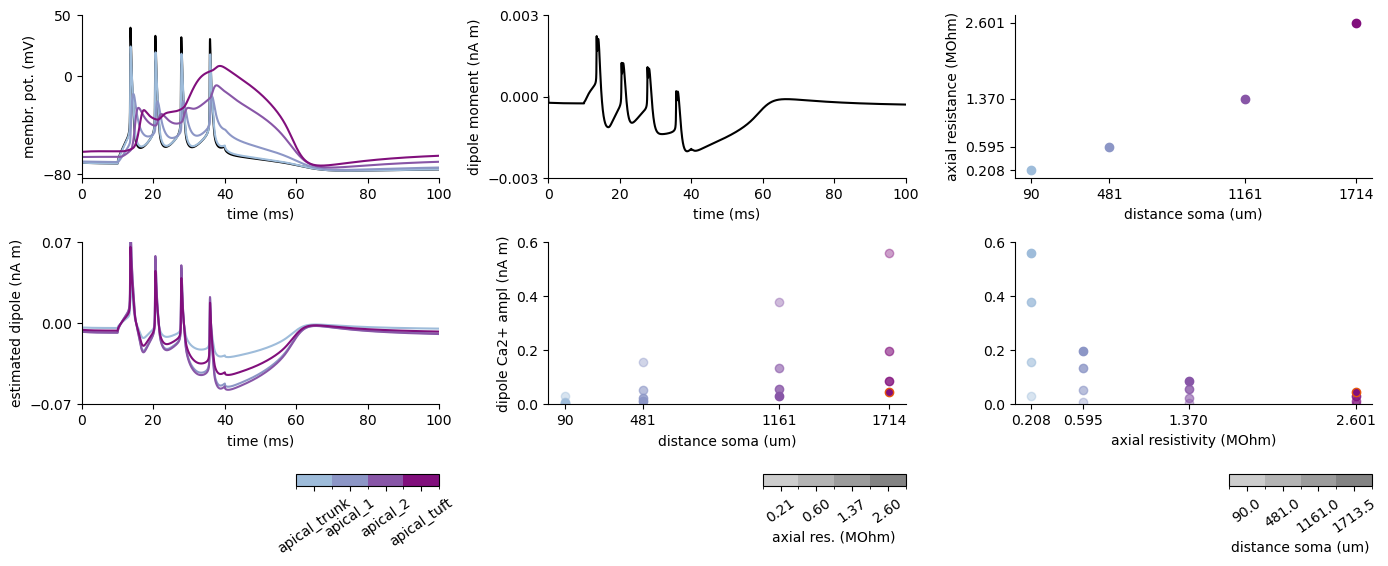

In [10]:
fig, ax = plt.subplots(2,3,figsize=(14,6))
ax[0,0].plot(t, v_soma, color='k')
for iv, v in enumerate(v_dend):
    ax[0,0].plot(t, v, color=l5_cols_tone[iv])
ax[0,0].set_ylabel('membr. pot. (mV)')
ax[0,1].plot(t, l5pyr.dipole*1e-6, color='k')
ax[0,1].set_ylabel('dipole moment (nA m)')
ax[0,0].set_xlabel('time (ms)')
ax[0,1].set_xlabel('time (ms)')
ax[0,0].set_xlim([0, 100])
ax[0,0].set_yticks([-80,0, 50])
# now, calculate the dipole moment pretending the Ca2+ spike occured in different sections
h.distance(sec = l5pyr._nrn_sections['soma'])

ztan = dict()
ri = dict()
dpl = dict()

sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for section in sections:

    
    ztan[section] = h.distance(.5, sec=l5pyr._nrn_sections[section])
    ri[section] = h.ri(1, sec=l5pyr._nrn_sections[section]) 
    dpl[section] = (v_soma.as_numpy()-v_dend[-1].as_numpy())/ri[section]*ztan[section]*1e-6
    

for s, section in enumerate(sections):

    ax[0,2].plot(ztan[section], ri[section], 'o', color=l5_cols_tone[s], label=section)
    ax[1,0].plot(t.as_numpy(), dpl[section], color=l5_cols_tone[s])
    

    for si, section_inner in enumerate(sections):
        dpl_fri = np.abs(np.min((v_soma.as_numpy()-v_dend[-1].as_numpy())/ri[section_inner]*ztan[section]*1e-6))
        dpl_fztan = np.abs(np.min((v_soma.as_numpy()-v_dend[-1].as_numpy())/ri[section]*ztan[section_inner]*1e-6))

        if section == 'apical_tuft' and section_inner == 'apical_tuft':
            markeredgecolor = '#e6550d'
        else:
            markeredgecolor = l5_cols_tone[s]
        ax[1,1].plot(ztan[section], dpl_fri, 'o', markerfacecolor=l5_cols_tone[s], markeredgecolor=markeredgecolor, alpha=alpha_level[si])
        ax[1,2].plot(ri[section], dpl_fztan, 'o', markerfacecolor=l5_cols_tone[s], markeredgecolor=markeredgecolor, alpha=alpha_level[si])

ax[1,0].set_ylim([-0.07, 0.07])
ax[1,0].set_yticks([-0.07, 0, 0.07])

ax[0,1].set_ylim([-0.002, 0.002])

ax[1,0].set_ylabel('estimated dipole (nA m)')
ax[1,0].set_xlabel('time (ms)')
ax[0,2].set_ylabel('axial resistance (MOhm)')
ax[0,2].set_xlabel('distance soma (um)')
ax[0,2].set_xticks(list(ztan.values()))
ax[0,2].set_yticks(list(ri.values()))
ax[1,1].set_xticks(list(ztan.values()))
ax[1,1].set_xlabel('distance soma (um)')
ax[1,1].set_ylabel('dipole Ca2+ ampl (nA m)')
ax[1,2].set_xlabel('axial resistivity (MOhm)')
ax[1,2].set_xticks(list(ri.values()))
ax[1,1].set_ylim([0, 0.6])
ax[1,2].set_ylim([0, 0.6])

ax[0,1].set_yticks([-0.003, 0, 0.003])
ax[0,1].set_xlim([0, 100])
ax[1,0].set_xlim([0, 100])

ax = ax.flatten()

cax0 = ax[-3].inset_axes([0.6, -.5, 0.4, 0.075])
cb0 = fig.colorbar(sm_neurons, cax=cax0, ticks=alpha_level, orientation='horizontal')
cb0.set_ticklabels(sections, rotation=35)

cax1 = ax[-2].inset_axes([0.6, -.5, 0.4, 0.075])
cb1 = fig.colorbar(sm, cax=cax1, ticks=alpha_level, orientation='horizontal')
cb1.set_ticklabels([f'{v:.2f}' for v in ri.values()], rotation=35)
cb1.set_label('axial res. (MOhm)')

cax2 = ax[-1].inset_axes([0.6, -.5, 0.4, 0.075])
cb2 = fig.colorbar(sm, cax=cax2, ticks=alpha_level, orientation='horizontal')
cb2.set_ticklabels(list(ztan.values()), rotation=35)
cb2.set_label('distance soma (um)')
for a in ax:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
fig.savefig(op.join(figpth,'dpl_ri_ztan.png'), dpi=300)
fig.savefig(op.join(figpth,'dpl_ri_ztan.pdf'))
fig.tight_layout()